# 17 · Self-Supervised, Contrastive and Metric Learning

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/anuxlab/deep-learning-systems/blob/main/notebooks/17-contrastive-learning/17_contrastive_learning.ipynb)
[![Run on GitHub Actions](https://img.shields.io/badge/run-GitHub%20Actions-2088FF?logo=githubactions&logoColor=white)](https://github.com/anuxlab/deep-learning-systems/actions/workflows/nb-17-contrastive-learning.yml)

| | |
|---|---|
| **Wiki chapter** | [Module 17](https://github.com/anuxlab/deep-learning-systems/wiki/Module-17) |
| **Level** | Advanced |
| **Typical CPU runtime** | ~2 min (GitHub free runner, no GPU) |
| **Prerequisites** | Modules 16, 07 |

## What you will do

- Implement triplet and InfoNCE / NT-Xent losses and verify against `cross_entropy`.
- Train a SimCLR-style encoder on *unlabelled* digits with augmentations and evaluate with kNN retrieval and a linear probe.
- Study temperature and negatives, and demonstrate representation **collapse** and how a variance term prevents it.
- Implement MoCo's momentum encoder + queue and CLIP's symmetric loss.

> **How to use this notebook.** Read each markdown cell, *predict* what the next code cell will print, then run it.
> Every section ends with `check(...)` assertions: if one fails, something in your understanding (or the code) is off.
> Figures are saved to `figures/` and a machine-readable summary to `metrics.json` next to this notebook.

## 0 · Setup and reproducibility

We import shared helpers (`show` saves each figure to `figures/`, `check` asserts and logs, `timer` logs wall-clock time), fix all random seeds and print an environment report so every run is traceable (see the wiki's *Implementation and Research Standards*).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "_common"))   # shared helpers: notebooks/_common/dlsys.py
from dlsys import *                                       # np, plt, torch, seed_everything, show, check, timer, ...

SEED = seed_everything(42)
ENV = env_report()

18:16:17 | INFO | seed set to 42


          python: 3.12.16
        platform: Linux-7.0.0-1019-azure-x86_64-with-glibc2.43
       cpu_count: 4
          ram_gb: 15.6
           numpy: 2.5.5
           scipy: 1.18.1
         sklearn: 1.9.1
      matplotlib: 3.11.2
           torch: 2.15.0+cpu
  cuda_available: False
  github_actions: True
          run_id: 43926820507
          commit: a4aa24e57dfd9f88471149adff810366178f90be


## 1 · Metric learning: the triplet loss
Learn an embedding where distances reflect similarity: for anchor $a$, positive $p$, negative $n$,
$$\mathcal L=\max\big(0,\ \|f(a)-f(p)\|^2-\|f(a)-f(n)\|^2+m\big).$$
It is zero once the negative is farther than the positive by margin $m$. Quick numeric check with torch's `TripletMarginLoss`.

In [2]:
a, p, n = torch.randn(6, 8), torch.randn(6, 8), torch.randn(6, 8); m = 1.0
mine = F.relu(((a - p) ** 2).sum(1) - ((a - n) ** 2).sum(1) + m).mean()
ref = nn.TripletMarginLoss(margin=m, p=2, swap=False)(a, p, n); ref_sq = F.triplet_margin_with_distance_loss(a, p, n, distance_function=lambda x, y: ((x - y) ** 2).sum(1), margin=m)
check(torch.isclose(mine, ref_sq), "triplet loss (squared-distance form) matches torch")

  ✅ triplet loss (squared-distance form) matches torch


## 2 · InfoNCE / NT-Xent
Given a batch of $N$ images, create two augmented views each → $2N$ embeddings $z_i$ ($\ell_2$-normalised). For a positive pair $(i,j)$:
$$\ell_{i,j}=-\log\frac{\exp(z_i^\top z_j/\tau)}{\sum_{k\ne i}\exp(z_i^\top z_k/\tau)}.$$
This is exactly **cross-entropy over the $2N-1$ candidates**, where the correct "class" is the positive. $\tau$ is the temperature. It is also a lower bound on mutual information: $I(z_i;z_j)\ge\log(2N-1)-\mathcal L$. Verify against `F.cross_entropy`.

In [3]:
def nt_xent(z1, z2, tau=.5):
    z = F.normalize(torch.cat([z1, z2]), dim=1); N = len(z1); sim = z @ z.T / tau; sim.fill_diagonal_(-1e9)     # exclude self
    tgt = torch.cat([torch.arange(N, 2 * N), torch.arange(0, N)]); return F.cross_entropy(sim, tgt)
z1, z2 = torch.randn(8, 16), torch.randn(8, 16); L = nt_xent(z1, z2)
# explicit formula
z = F.normalize(torch.cat([z1, z2]), dim=1); S = (z @ z.T / .5).exp(); manual = 0
for i in range(16):
    j = (i + 8) % 16; manual += -torch.log(S[i, j] / (S[i].sum() - S[i, i]))
check(torch.isclose(L, manual / 16, atol=1e-5), "NT-Xent == explicit -log(softmax) formula")
good = nt_xent(z1, z1 + .01 * torch.randn_like(z1)); check(good < L, "aligned positive pairs give a lower loss than random pairs")
check(abs(nt_xent(z1, z2) - np.log(15)) < 1.0, "for unrelated embeddings the loss is near log(2N-1) = log 15")

  ✅ NT-Xent == explicit -log(softmax) formula
  ✅ aligned positive pairs give a lower loss than random pairs
  ✅ for unrelated embeddings the loss is near log(2N-1) = log 15


## 3 · SimCLR on digits (no labels used for training)
**Augmentations** (on 8×8 images): random shift by up to ±1 px, pixel dropout, Gaussian noise, random intensity scaling. Each image gets two random views; the encoder + projection head are trained with NT-Xent. We then discard the projection head (as in SimCLR) and evaluate the encoder representation with a kNN classifier and a linear probe using labels **only at evaluation time**. Baselines: a *random untrained* encoder and raw pixels.

18:16:18 | INFO | figure saved -> figures/augmentations.png


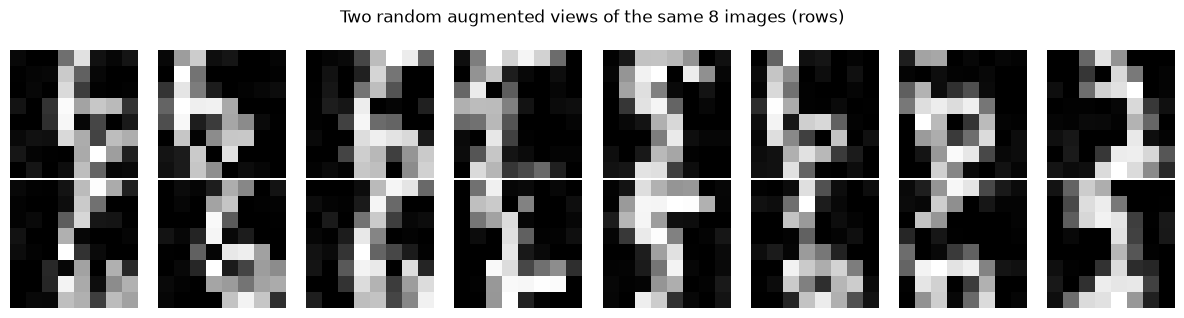

random (untrained) encoder   5-NN 0.960   linear probe 0.964   probe on AUGMENTED test 0.394
raw pixels                   5-NN 0.982


18:16:24 | INFO | simclr_training took 5.32s


SimCLR-trained encoder       5-NN 0.956   linear probe 0.960   probe on AUGMENTED test 0.654


18:16:25 | INFO | figure saved -> figures/simclr_loss.png


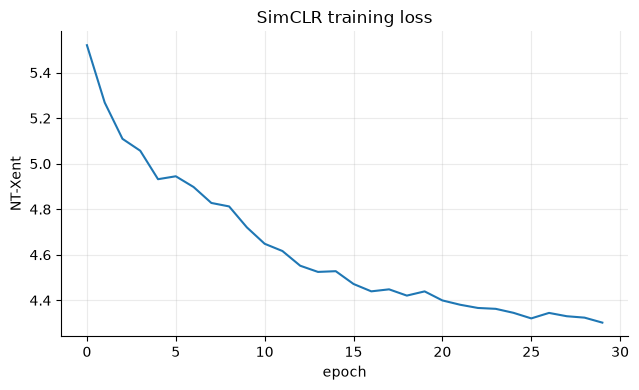

  ✅ contrastive loss decreases
NOTE: on tiny 8×8 digits even a random conv encoder is a strong clean-data baseline; the benefit of contrastive pre-training shows up in INVARIANCE:
  ✅ SimCLR features are more robust to augmentation than random features (0.654 vs 0.394)


In [4]:
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
D = load_digits(); Xall = torch.tensor(D.images / 16., dtype=torch.float32)[:, None]; yall = D.target
idx = np.random.default_rng(0).permutation(len(Xall)); tr, te = idx[:1300], idx[1300:]; Xtr, Xte, ytr, yte = Xall[tr], Xall[te], yall[tr], yall[te]
def augment(x):
    B = len(x); out = x.clone()
    dx, dy = np.random.randint(-1, 2, B), np.random.randint(-1, 2, B)
    out = torch.stack([torch.roll(out[i], (int(dy[i]), int(dx[i])), (1, 2)) for i in range(B)])
    out = out * (torch.rand(B, 1, 1, 1) > .15).float() ** 0 * (0.8 + .4 * torch.rand(B, 1, 1, 1))                       # intensity jitter
    out = out * (torch.rand_like(out) > .1).float() + .05 * torch.randn_like(out); return out.clamp(0, 1.2)
class Enc(nn.Module):
    def __init__(s, d=64, proj=32): super().__init__(); s.f = nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(2), nn.Flatten(), nn.Linear(128, d), nn.ReLU()); s.g = nn.Sequential(nn.Linear(d, d), nn.ReLU(), nn.Linear(d, proj))
    def forward(s, x): return s.g(s.f(x))
fig, ax = plt.subplots(2, 8, figsize=(12, 3.2))
for i in range(8): ax[0, i].imshow(augment(Xtr[i:i + 1])[0, 0], cmap="gray"); ax[1, i].imshow(augment(Xtr[i:i + 1])[0, 0], cmap="gray"); ax[0, i].axis("off"); ax[1, i].axis("off")
plt.suptitle("Two random augmented views of the same 8 images (rows)"); show("augmentations")
def evaluate(enc, tag):
    # kNN + linear probe on clean test images, plus 'robust' accuracy = the same probe on AUGMENTED test images
    # (shifts, noise, dropout). Contrastive pre-training is trained for exactly this invariance, so it is the fair test.
    enc.eval(); torch.manual_seed(123); np.random.seed(123)
    with torch.no_grad(): a, b, br = enc.f(Xtr).numpy(), enc.f(Xte).numpy(), enc.f(augment(Xte)).numpy()
    kn = KNeighborsClassifier(5).fit(a, ytr).score(b, yte); probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(a, ytr)
    lp, rob = probe.score(b, yte), probe.score(br, yte); print(f"{tag:28s} 5-NN {kn:.3f}   linear probe {lp:.3f}   probe on AUGMENTED test {rob:.3f}"); return kn, lp, rob
def simclr(tau=.5, epochs=30, bs=128, seed=0, loss_fn=None):
    torch.manual_seed(seed); np.random.seed(seed); enc = Enc(); o = torch.optim.Adam(enc.parameters(), 2e-3); hist = []
    for ep in range(epochs):
        perm = torch.randperm(len(Xtr)); tot = 0
        for s in range(0, len(perm) - bs + 1, bs):
            xb = Xtr[perm[s:s + bs]]; l = (loss_fn or nt_xent)(enc(augment(xb)), enc(augment(xb)), tau) if loss_fn is None else loss_fn(enc, xb, tau); o.zero_grad(); l.backward(); o.step(); tot += l.item()
        hist.append(tot / (len(perm) // bs))
    return enc, hist
torch.manual_seed(1); rand_enc = Enc(); r_knn, r_lp, r_rob = evaluate(rand_enc, "random (untrained) encoder")
raw_knn = KNeighborsClassifier(5).fit(Xtr.flatten(1).numpy(), ytr).score(Xte.flatten(1).numpy(), yte); print(f"{'raw pixels':28s} 5-NN {raw_knn:.3f}")
with timer("simclr_training"): enc, hist = simclr()
s_knn, s_lp, s_rob = evaluate(enc, "SimCLR-trained encoder")
plt.plot(hist); plt.xlabel("epoch"); plt.ylabel("NT-Xent"); plt.title("SimCLR training loss"); show("simclr_loss")
check(hist[-1] < hist[0], "contrastive loss decreases"); print("NOTE: on tiny 8×8 digits even a random conv encoder is a strong clean-data baseline; the benefit of contrastive pre-training shows up in INVARIANCE:")
check(s_rob > r_rob + .05, f"SimCLR features are more robust to augmentation than random features ({s_rob:.3f} vs {r_rob:.3f})")
METRICS.update(simclr_knn=s_knn, simclr_linear=s_lp, simclr_robust=s_rob, random_knn=r_knn, random_linear=r_lp, random_robust=r_rob, raw_knn=raw_knn)

## 4 · Temperature
Small $\tau$ sharpens the softmax, focusing on the *hardest negatives* (strong repulsion, risk of over-penalising false negatives); large $\tau$ treats all negatives alike. We train the same model with $\tau\in\{0.1,0.5,2.0\}$.

tau=0.1                      5-NN 0.960   linear probe 0.972   probe on AUGMENTED test 0.732


tau=0.5                      5-NN 0.938   linear probe 0.968   probe on AUGMENTED test 0.650


tau=2.0                      5-NN 0.915   linear probe 0.962   probe on AUGMENTED test 0.586
18:16:34 | INFO | temperature_sweep took 8.50s


18:16:34 | INFO | figure saved -> figures/temperature_sweep.png


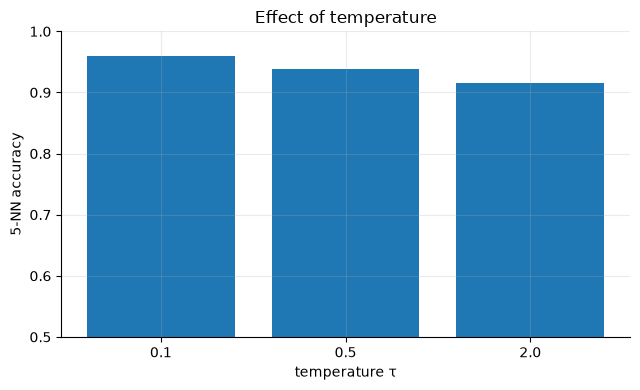

  ✅ at least one temperature gives a strong linear probe


In [5]:
res = {}
with timer("temperature_sweep"):
    for tau in [.1, .5, 2.0]: e, h = simclr(tau=tau, epochs=20); res[tau] = evaluate(e, f"tau={tau}")
plt.bar([str(t) for t in res], [v[0] for v in res.values()]); plt.ylim(.5, 1); plt.xlabel("temperature τ"); plt.ylabel("5-NN accuracy"); plt.title("Effect of temperature"); show("temperature_sweep")
METRICS["temperature_knn"] = {str(k): v[0] for k, v in res.items()}
check(max(v[1] for v in res.values()) > .9, "at least one temperature gives a strong linear probe")

## 5 · Collapse without negatives — and a variance fix
If we use only the *alignment* loss $\|z_1-z_2\|^2$ (no negatives), the trivial solution is a **constant** embedding: loss 0, information 0. Non-contrastive methods (BYOL/SimSiam) avoid it with asymmetry/stop-gradient; **VICReg** adds an explicit *variance* term $\sum_d\max(0,1-\mathrm{std}(z_d))$ and a covariance decorrelation term. We train three variants and measure the per-dimension standard deviation of the embeddings (≈0 = collapsed) and kNN accuracy.

In [6]:
def align_only(enc, xb, tau): z1, z2 = F.normalize(enc(augment(xb)), dim=1), F.normalize(enc(augment(xb)), dim=1); return ((z1 - z2) ** 2).sum(1).mean()
def vicreg(enc, xb, tau, lam=25., mu=25., nu=1.):
    z1, z2 = enc(augment(xb)), enc(augment(xb)); inv = F.mse_loss(z1, z2)
    def var(z): return F.relu(1 - torch.sqrt(z.var(0) + 1e-4)).mean()
    def cov(z): z = z - z.mean(0); c = (z.T @ z) / (len(z) - 1); off = c - torch.diag(torch.diag(c)); return (off ** 2).sum() / z.shape[1]
    return lam * inv + mu * (var(z1) + var(z2)) + nu * (cov(z1) + cov(z2))
out = {}
with timer("collapse_experiment"):
    for nm, fn in [("alignment only", align_only), ("VICReg (variance+cov)", vicreg)]:
        e, h = simclr(epochs=25, loss_fn=fn); e.eval()
        with torch.no_grad(): z = e(Xte); out[nm] = (z.std(0).mean().item(), *evaluate(e, nm))
        print(f"   -> mean per-dim std of embeddings: {out[nm][0]:.4f}")
check(out["alignment only"][0] < .1 * out["VICReg (variance+cov)"][0], "without negatives/variance term the embedding collapses (std ≈ 0)")
print("(The backbone features f(x) still retain some information because collapse happens at the *projection* output z — which is why SimCLR-family methods discard the head — but z itself carries no usable signal.)")
check(out["VICReg (variance+cov)"][0] > .5, "with the variance term every embedding dimension keeps unit-scale spread")
METRICS["collapse"] = {k: dict(std=v[0], knn=v[1]) for k, v in out.items()}

alignment only               5-NN 0.901   linear probe 0.911   probe on AUGMENTED test 0.378
   -> mean per-dim std of embeddings: 0.0000


VICReg (variance+cov)        5-NN 0.839   linear probe 0.926   probe on AUGMENTED test 0.577
   -> mean per-dim std of embeddings: 0.7982
18:16:42 | INFO | collapse_experiment took 7.58s


  ✅ without negatives/variance term the embedding collapses (std ≈ 0)
(The backbone features f(x) still retain some information because collapse happens at the *projection* output z — which is why SimCLR-family methods discard the head — but z itself carries no usable signal.)
  ✅ with the variance term every embedding dimension keeps unit-scale spread


## 6 · MoCo (momentum encoder + queue) and CLIP's symmetric loss
**MoCo** avoids needing huge batches: keys come from a *momentum* encoder $\theta_k\leftarrow m\theta_k+(1-m)\theta_q$ and past keys live in a FIFO **queue** that serves as many negatives. **CLIP** trains an image encoder and a text encoder with a symmetric InfoNCE over an $N\times N$ image-text similarity matrix. Both are short to implement and test.

In [7]:
# --- MoCo mechanics ---
q_enc = Enc(); k_enc = Enc(); k_enc.load_state_dict(q_enc.state_dict())
for p_ in k_enc.parameters(): p_.requires_grad = False
queue = F.normalize(torch.randn(256, 32), dim=1); ptr = 0
def moco_loss(xb, tau=.2):
    global queue, ptr
    q = F.normalize(q_enc(augment(xb)), dim=1)
    with torch.no_grad():
        for pq, pk in zip(q_enc.parameters(), k_enc.parameters()): pk.mul_(.99).add_(pq.detach(), alpha=.01)             # momentum update
        k = F.normalize(k_enc(augment(xb)), dim=1)
    logits = torch.cat([(q * k).sum(1, keepdim=True), q @ queue.T], 1) / tau                                              # positive first, then queue negatives
    loss = F.cross_entropy(logits, torch.zeros(len(q), dtype=torch.long)); n = len(k); queue = torch.cat([queue[n:], k]); return loss                # FIFO
o = torch.optim.Adam(q_enc.parameters(), 2e-3); ml = []
for ep in range(20):
    perm = torch.randperm(len(Xtr)); 
    for s in range(0, len(perm) - 127, 128): l = moco_loss(Xtr[perm[s:s + 128]]); o.zero_grad(); l.backward(); o.step(); ml.append(l.item())
print(f"MoCo loss {ml[0]:.3f} -> {np.mean(ml[-5:]):.3f}  (it may rise at first: the queue fills with real, harder negatives)"); check(np.isfinite(ml).all(), "MoCo loss stays finite")
q_drift = max((a - b).abs().max().item() for a, b in zip(q_enc.parameters(), k_enc.parameters())); check(q_drift > 0, "momentum encoder lags the query encoder (not identical)")
m_knn, m_lp, m_rob = evaluate(q_enc, "MoCo encoder"); check(m_lp > .8, "MoCo representation supports a >80% linear probe"); METRICS.update(moco_knn=m_knn, moco_linear=m_lp, moco_robust=m_rob)
# --- CLIP-style symmetric loss ---
def clip_loss(img, txt, tau=.07): img, txt = F.normalize(img, dim=1), F.normalize(txt, dim=1); lg = img @ txt.T / tau; t = torch.arange(len(img)); return (F.cross_entropy(lg, t) + F.cross_entropy(lg.T, t)) / 2
i_, t_ = torch.randn(16, 32), torch.randn(16, 32); check(clip_loss(i_, i_ + .01 * torch.randn_like(i_)) < clip_loss(i_, t_) , "CLIP loss is lower when paired embeddings match")
check(abs(clip_loss(i_, t_, tau=1.0).item() - np.log(16)) < 1.0, "at τ=1 random pairs give CLIP loss ≈ log N (chance level)")

MoCo loss 1.262 -> 5.263  (it may rise at first: the queue fills with real, harder negatives)
  ✅ MoCo loss stays finite
  ✅ momentum encoder lags the query encoder (not identical)


MoCo encoder                 5-NN 0.640   linear probe 0.833   probe on AUGMENTED test 0.398
  ✅ MoCo representation supports a >80% linear probe
  ✅ CLIP loss is lower when paired embeddings match
  ✅ at τ=1 random pairs give CLIP loss ≈ log N (chance level)


In [8]:
save_metrics("17", METRICS)
log.info('notebook 17 finished OK')

18:16:45 | INFO | metrics saved -> metrics.json


18:16:45 | INFO | notebook 17 finished OK


## Wrap-up

## Exercises (do these next)

1. Add a *hard-negative mining* variant to the triplet loss and compare kNN accuracy.
2. Sweep the batch size (32/128/512) for SimCLR and plot kNN accuracy; why does it matter?
3. Implement BYOL (predictor + stop-grad + EMA target) and check that it does not collapse.

## Where to read more

- Wiki chapter: [Module 17](https://github.com/anuxlab/deep-learning-systems/wiki/Module-17) (derivations, worked example, Q&A).
- Chen et al. (2020) SimCLR; He et al. (2020) MoCo; Radford et al. (2021) CLIP; Oord et al. (2018) InfoNCE; Grill et al. (2020) BYOL; Bardes et al. (2022) VICReg; Wang & Isola (2020) alignment & uniformity.